In [1]:
import librosa
import amostragem as amos
import IPython.display as ipd
import numpy as np
import math
import matplotlib.pyplot as plt

/home/toto/workspace/sinais/lab4/amostragem.py:26: SyntaxWarning: invalid escape sequence '\O'
  ax.set_xlabel('$\Omega$ [rad]', fontsize=10)
/home/toto/workspace/sinais/lab4/amostragem.py:27: SyntaxWarning: invalid escape sequence '\O'
  ax.set_ylabel('|$Y(e^{j\Omega})$|', fontsize=10)


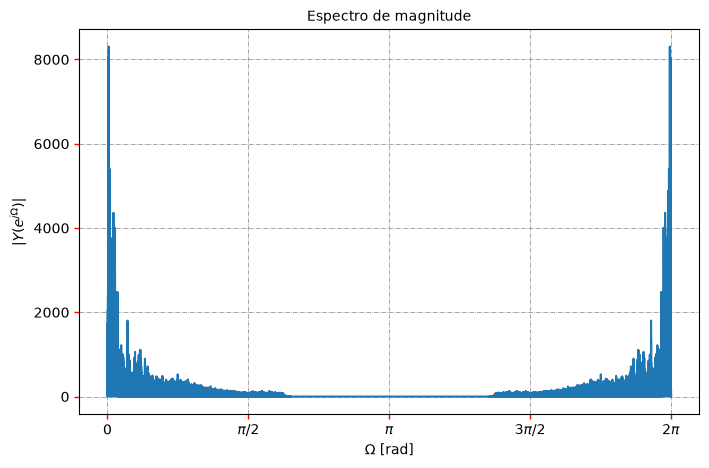

In [2]:
filename = "Dire_Straits_Money_For_Nothing.mp3"
fs = 44100
y, sr = librosa.load(filename, sr=fs , duration=60, offset=35.6)
Y,w = amos.grafico(amos.espectro(y),fs)
ipd.Audio(y,rate=sr)


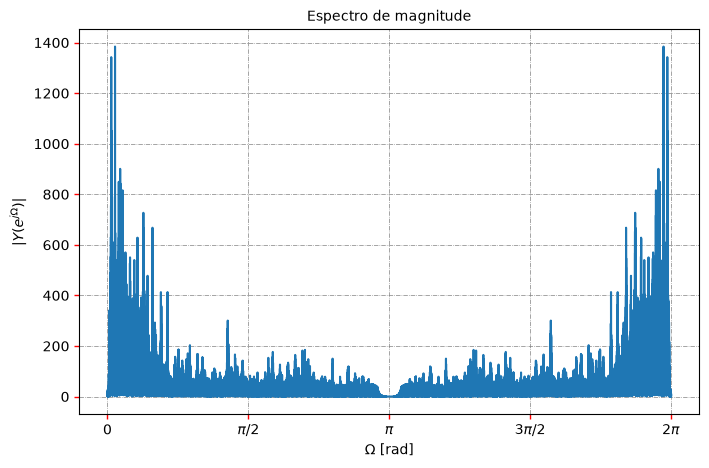

In [3]:
fs = 44100
M = 6
fs = fs/M

y1, fs = librosa.load(filename, sr=fs , duration=60, offset=35.6)
Y,w = amos.grafico(amos.espectro(y1),fs)
ipd.Audio(y1,rate=sr)




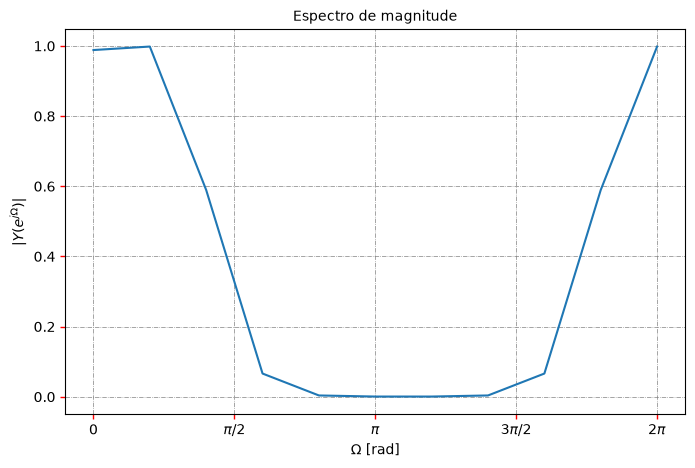

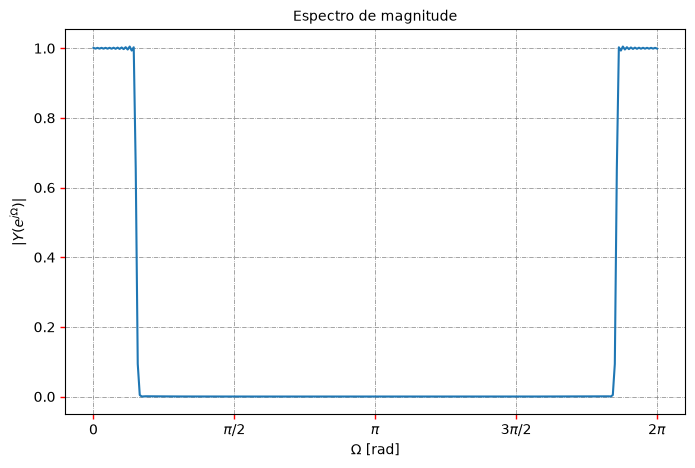

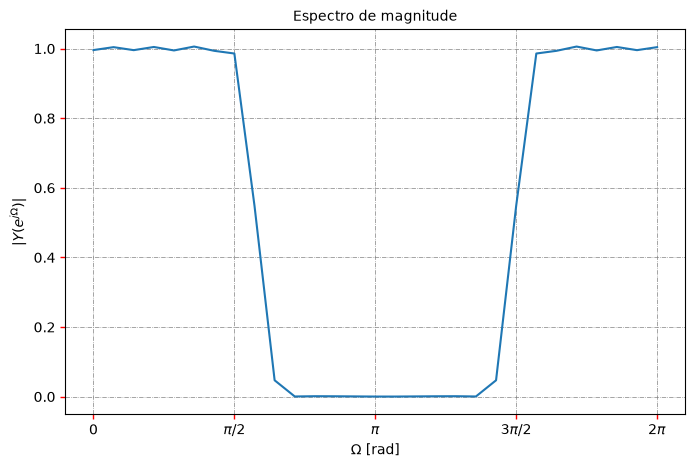

In [4]:
wp = [0.45,0.45,1.5]
wr = [2,0.5,2]
Y = []
fs = 44100
ysig, sr = librosa.load(filename, sr=fs , duration=60, offset=35.6)

for i in range(0,len(wp)):
    y = amos.kaiser(wp[i],wr[i])
    Y.append(amos.espectro(y))
    amos.grafico(Y[i],fs)

[1.00112105 1.00112081 1.00112057 ... 0.99887658 0.99887635 0.99887611]


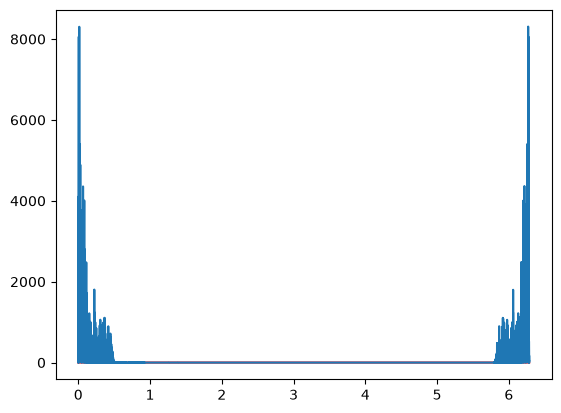

In [12]:
y, sr = librosa.load(filename, sr=fs , duration=60, offset=35.6)
Y1 = amos.espectro(y)
w = np.linspace(0,2*math.pi,Y1.size)
#ax,fig = amos.grafico(Y1,fs)

wfiltro = np.linspace(0,2*math.pi,Y[1].size)


filtro_interpolado = np.interp(w, wfiltro, Y[1])
#ax.plot(w,filtro_interpolado)


print(filtro_interpolado)
H = filtro_interpolado*Y1
plt.plot(w,filtro_interpolado,"red")
plt.plot(w,H)

In [6]:
len(filtro_interpolado)

2646000

In [7]:
y_dec = []
sr = fs/6

y1 = np.real(np.fft.ifft(H))
y_dec = amos.decimacao(y1,6)
ipd.Audio(y_dec,rate=sr)
amos.espectro(y_dec,sr)


TypeError: espectro() takes 1 positional argument but 2 were given

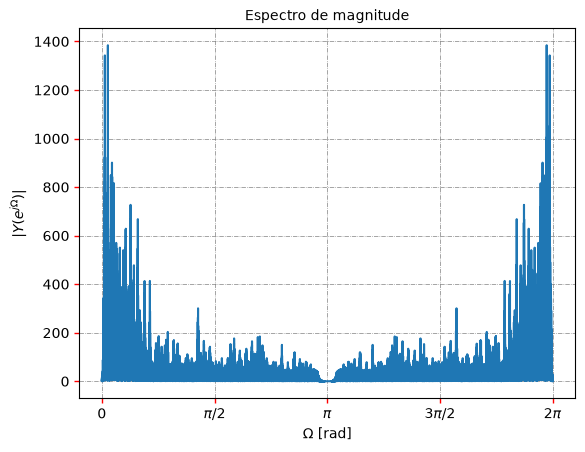

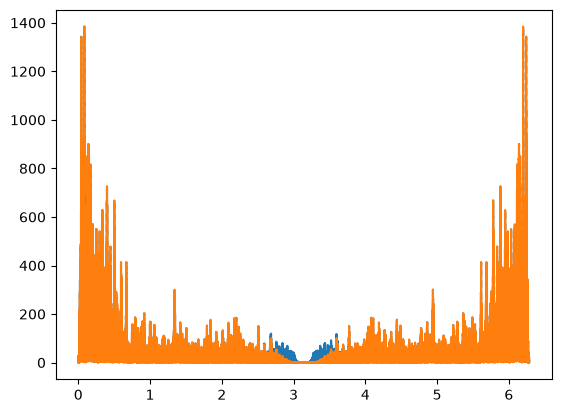

In [ ]:
fs = 44100
M = 6
sr = fs/M

y, sr = librosa.load(filename, sr=sr , duration=60, offset=35.6)
Y,w = amos.espectro(y,sr)
ipd.Audio(y,rate=sr)
fig, ax = plt.subplots()
ax.plot(w, Y,"--")
ax.plot(w,np.abs(np.fft.fft(y_dec)))